In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
##modelling 
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor 
from xgboost import XGBRegressor 
import warnings


In [2]:
%pip install catboost


Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [15]:
df = pd.read_csv('stud.csv')

In [26]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [36]:
X = df.drop('math_score', axis=1)

In [37]:
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [38]:
Y=df['math_score']

In [39]:
Y

0      72
1      69
2      90
3      47
4      76
       ..
995    88
996    62
997    59
998    68
999    77
Name: math_score, Length: 1000, dtype: int64

In [46]:
num_features = X.select_dtypes(exclude="str").columns
cat_features = X.select_dtypes(include="str").columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder",oh_transformer,cat_features),
        ( "standardscaler",numeric_transformer,num_features),
    ]
)


AttributeError: 'numpy.ndarray' object has no attribute 'select_dtypes'

In [47]:
X = preprocessor.fit_transform(X)


ValueError: Specifying the columns using strings is only supported for dataframes.

In [ ]:
X

array([[ 1.        ,  0.        ,  0.        , ...,  1.        ,
         0.19399858,  0.39149181],
       [ 1.        ,  0.        ,  0.        , ...,  0.        ,
         1.42747598,  1.31326868],
       [ 1.        ,  0.        ,  0.        , ...,  1.        ,
         1.77010859,  1.64247471],
       ...,
       [ 1.        ,  0.        ,  0.        , ...,  0.        ,
         0.12547206, -0.20107904],
       [ 1.        ,  0.        ,  0.        , ...,  0.        ,
         0.60515772,  0.58901542],
       [ 1.        ,  0.        ,  0.        , ...,  1.        ,
         1.15336989,  1.18158627]], shape=(1000, 19))

In [ ]:
X.shape

(1000, 19)

In [49]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
x_train.shape,x_test.shape


((800, 19), (200, 19))

In [50]:
def evaluate_model(true,predicted):
    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse=np.sqrt(mean_squared_error(true,predicted))
    r2_square=r2_score(true,predicted)
    return mae,rmse,r2_square


In [51]:
models= {
    "Linear Regression":LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoostING Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()

}
model_list=[]
r2_list=[]

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(x_train,y_train)

    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)


    model_train_mae , model_train_rmse , model_train_r2 = evaluate_model(y_train,y_train_pred)

    model_test_mae , model_test_rmse , model_test_r2 = evaluate_model(y_test,y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('model performance for training set')
    print('-root mean squared error: {:.4f}'.format(model_train_rmse))
    print('-mean absolute error:{:.4f}'.format(model_train_mae))
    print('-r2 score:{:.4f}'.format(model_train_r2))

    print("-------------------------------------------------------------")

    print("model performrnace for test set")
    print('-root mean squared error: {:.4f}'.format(model_test_rmse))
    print('-mean absolute error:{:.4f}'.format(model_test_mae))
    print('-r2 score:{:.4f}'.format(model_test_r2))

    print("="*35)
    print('\n')



Linear Regression
model performance for training set
-root mean squared error: 5.3231
-mean absolute error:4.2667
-r2 score:0.8743
-------------------------------------------------------------
model performrnace for test set
-root mean squared error: 5.3940
-mean absolute error:4.2148
-r2 score:0.8804


Lasso
model performance for training set
-root mean squared error: 6.5938
-mean absolute error:5.2063
-r2 score:0.8071
-------------------------------------------------------------
model performrnace for test set
-root mean squared error: 6.5197
-mean absolute error:5.1579
-r2 score:0.8253


Ridge
model performance for training set
-root mean squared error: 5.3233
-mean absolute error:4.2650
-r2 score:0.8743
-------------------------------------------------------------
model performrnace for test set
-root mean squared error: 5.3904
-mean absolute error:4.2111
-r2 score:0.8806


K-Neighbors Regressor
model performance for training set
-root mean squared error: 5.7088
-mean absolute erro

In [55]:
##result
pd.DataFrame(list(zip(model_list, r2_list)), columns=['model name', 'r2_score']).sort_values(by=['r2_score'],ascending=False)

,model name,r2_score


In [56]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(x_train, y_train)
y_pred = lin_model.predict(x_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy of the model is %.2f" %score)


Accuracy of the model is 88.04


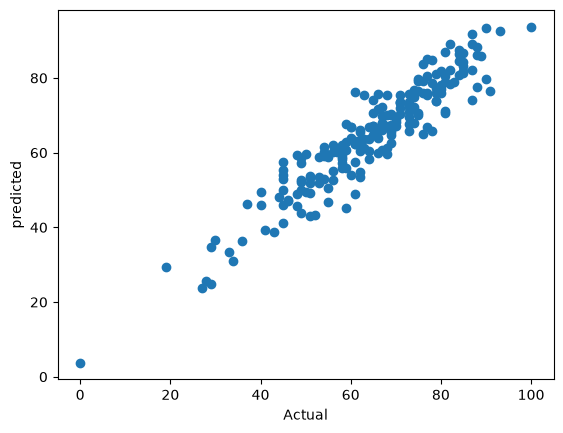

In [57]:
plt.scatter(y_test,y_pred);
plt.xlabel('Actual');
plt.ylabel('predicted');



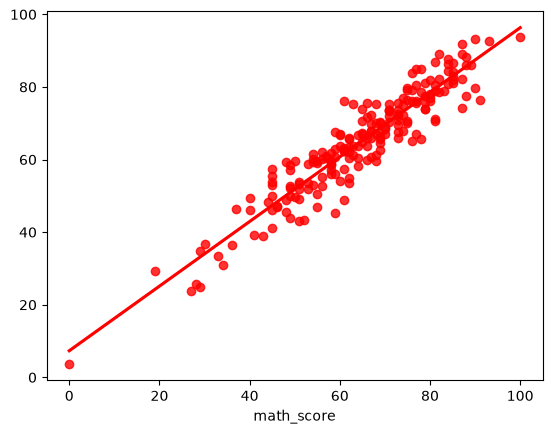

In [58]:
sns.regplot(x=y_test,y=y_pred,ci=None,color='red');

In [59]:
pred_df=pd.DataFrame({'Actual value':y_test,'predicted value':y_pred,'Differenece':y_test-y_pred})
pred_df

,Actual value,predicted value,Differenece
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
...,...,...,...
408,52,43.409149,8.590851
332,62,62.152214,-0.152214
208,74,67.888395,6.111605
613,65,67.022287,-2.022287
